# 06 · 短训练、曲线与 checkpoint

## 学习目标

运行完整 PPO 管线，读取训练 CSV 和 checkpoint。256 步只用于执行验收，不能据此判断收敛。

本 Notebook 直接运行已补全的 exercise 实现；修改 `.py` 后重新运行相关 Cell。

## 环境准备

先按 [使用指南](README.md) 安装 `.[dev,notebook]`，选择项目 Kernel。

In [1]:
from pathlib import Path
import os
import sys
import torch
import numpy as np

# 从仓库根目录或 notebooks/ 打开都可；不要依赖某台机器的绝对路径。
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'pyproject.toml').exists()
                     and (p / 'src/ppo_pendulum').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('请从项目目录启动 JupyterLab')
os.chdir(PROJECT_ROOT)
%load_ext autoreload
%autoreload 2
torch.manual_seed(7)
np.random.seed(7)
print('Python:', sys.executable)
print('Project:', PROJECT_ROOT.name)

Python: /Users/matt/Documents/Codex/2026-11-15/referenced-chatgpt-conversation-this-is-an-2/work/.venv/bin/python
Project: ppo-inverted-pendulum


## 1. 参数与短训练

输出写到 `runs/notebook/`。重复运行会覆盖同名输出；想保留实验时修改目录。默认只运行 256 步，学习收敛可后续尝试 20,000/200,000 步。

In [2]:
from ppo_pendulum.config import PPOConfig
from ppo_pendulum.exercises.trainer import train
from ppo_pendulum.evaluate import evaluate
config = PPOConfig(total_timesteps=256, rollout_steps=128,
                   update_epochs=2, minibatch_size=64, seed=7,
                   output_dir=PROJECT_ROOT / 'runs/notebook/exercise')
checkpoint_path = train(config)
assert checkpoint_path.exists()
print('checkpoint:', checkpoint_path.relative_to(PROJECT_ROOT))

step=    128 actor=+0.0009 critic=12.1824 episodes=11
step=    256 actor=-0.0042 critic=15.5563 episodes=23
checkpoint: runs/notebook/exercise/final.pt


## 2. 读取 loss 与回报

每行对应一次 rollout/update；只有两个采样点的线段仅说明记录通畅，不足以说明训练趋势。

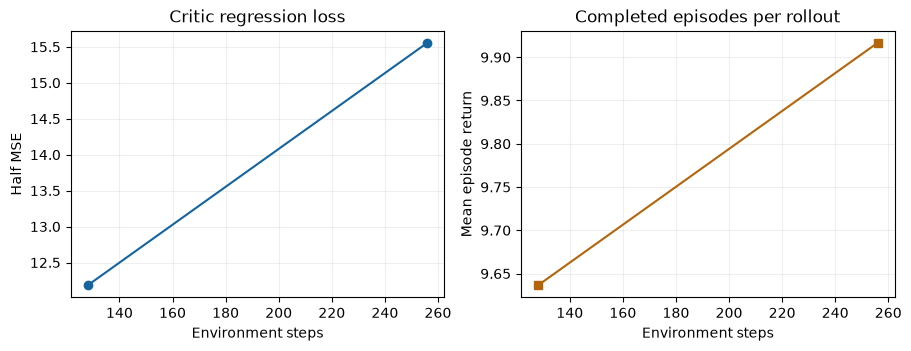

In [3]:
import csv
import matplotlib.pyplot as plt
with (config.output_dir / 'metrics.csv').open() as file:
    rows = list(csv.DictReader(file))
steps = [int(row['step']) for row in rows]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), constrained_layout=True)
axes[0].plot(steps, [float(row['critic_loss']) for row in rows], 'o-', color='#1464a0')
axes[0].set(title='Critic regression loss', xlabel='Environment steps', ylabel='Half MSE')
returns = [float(row['mean_recent_return']) if row['mean_recent_return'] else np.nan for row in rows]
axes[1].plot(steps, returns, 's-', color='#b4650a')
axes[1].set(title='Completed episodes per rollout', xlabel='Environment steps', ylabel='Mean episode return')
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()
assert len(rows) == (config.total_timesteps + config.rollout_steps - 1) // config.rollout_steps

## 3. 重载 checkpoint 并评估

不打开图形窗口。评估使用均值动作，和训练时的随机采样策略不同。

In [4]:
mean_return, mean_length = evaluate(checkpoint_path, episodes=2, render=False)
print(f'mean_return={mean_return:.2f}, mean_length={mean_length:.1f}')
assert np.isfinite(mean_return) and 1 <= mean_length <= config.max_episode_steps

mean_return=18.50, mean_length=19.5


## 检查

这一页已经完整执行 exercise 工程：MuJoCo 环境采样、GAE、PPO
mini-batch 更新、CSV 记录、checkpoint 保存和重新载入评估。256 步只验证
管线；把 `total_timesteps` 调到 20,000 或 200,000 才适合观察学习效果。

## 下一步

完成练习实现，使用多个 seed 评估长期训练；保留 config 与 CSV，避免只观察单个最好结果。

公式对照：[PPO_FORMULAS.md](../docs/PPO_FORMULAS.md)。